# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
class Card:
    def __init__(self, suit, rank):
        self.suit = suit
        self.rank = rank
    def get_blackjack_value(self):
        if self.rank in ["J", "Q", "K"]:
            return 10
        elif self.rank == "A":
            return 11
        return int(self.rank)
    def get_high_low_value(self):
        if self.rank in ["2", "3", "4", "5", "6"]:
            return 1
        elif self.rank in ["7", "8", "9"]:
            return 0
        else:
            return -1
    def __repr__(self):
        return f"{self.rank}{self.suit[0]}"

class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.needs_shuffle = False
        self.build_and_shuffle()
    def build_and_shuffle(self):
        Suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        Ranks = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"]
        self.cards = [Card(s, r) for _ in range(self.num_decks) for s in Suits for r in Ranks]
        random.shuffle(self.cards)
        cut_index = random.randint(int(len(self.cards) * 0.65), int(len(self.cards)*0.75))
        self.cards.insert(cut_index, "PlasticCard")
        self.needs_shuffle = False
    def draw(self):
        if not self.cards:
            self.build_and_shuffle()
        card = self.cards.pop(0)
        if card == "PlasticCard":
            self.needs_shuffle = True
            return self.draw()
        return card

In [92]:
class Player:
    def __init__(self, name, chips=100):
        self.name = name
        self.chips = chips
        self.hand = []
    def hand_value(self):
        total = sum(card.get_blackjack_value() for card in self.hand)
        aces = sum(1 for card in self.hand if card.rank == "A")
        while total > 21 and aces > 0:
            total -= 10
            aces -= 1
        return total
    def decide_hit(self, running_count=0):
        raise NotImplementedError("Subclasses need to input decide hit.")

class DealerPlayer(Player):
    def decide_hit(self, running_count=0):
        return self.hand_value() < 17

class HumanPlayer(Player):
    def decide_hit(self, running_count=0):
        print(f"{self.name} hand: {self.hand}")
        print(f"Total: {self.hand_value()}")
        
        choice = input("Hit or Stay? (h/s): ").strip().lower()
        return choice == "h"
class CountingPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold
    def decide_hit(self, running_count=0):
        score = self.hand_value()
        if score <= 11:
            return True
        if score >= 17:
            return False
        return running_count < self.threshold

class IndividualPlayer(Player):
    def __init__(self, name, chips=100, threshold=0):
        super().__init__(name, chips)
    def decide_hit(self, running_count=0):
        return self.hand_value() < 17

In [93]:
def run_50_round_game(threshold=0, starting_chips=100, bet=1, verbose=False, player_class=CountingPlayer):
    deck = Deck(num_decks=6)
    running_count = 0

    strategy_player = player_class("StrategyPlayer", chips=starting_chips, threshold=threshold)
    other_players = [DealerPlayer(f"Bot_{i}", chips=starting_chips) for i in range(3)]
    all_players = [strategy_player] + other_players
    dealer = DealerPlayer("HouseDealer", chips=10000)
    def deal_card(target_hand):
        nonlocal running_count
        card = deck.draw()
        running_count += card.get_high_low_value()
        target_hand.append(card)
    for round_num in range(1, 51):
        if strategy_player.chips < bet:
            break
        if deck.needs_shuffle:
            deck.build_and_shuffle()
            running_count = 0
        for p in all_players + [dealer]:
            p.hand = []
        for _ in range(2):
            for p in all_players + [dealer]:
                deal_card(p.hand)
        for p in all_players:
            while p.hand_value() < 21 and p.decide_hit(running_count):
                deal_card(p.hand)
        while dealer.decide_hit():
            deal_card(dealer.hand)
        dealer_score = dealer.hand_value()
        for p in all_players:
            p_score = p.hand_value()
            if p_score > 21:
                p.chips -= bet
            elif dealer_score > 21 or p_score > dealer_score:
                p.chips += bet
            elif p_score < dealer_score:
                p.chips -= bet
        if verbose:
            print(f"Round {round_num} | Count: {running_count} | Strategy Chips: {strategy_player.chips}")
    return strategy_player.chips - starting_chips

Average winnings per round:, -0.1024
Standard Deviation: 6.98
Prediction of amount win: 22.00% | amount loss: 74.00%


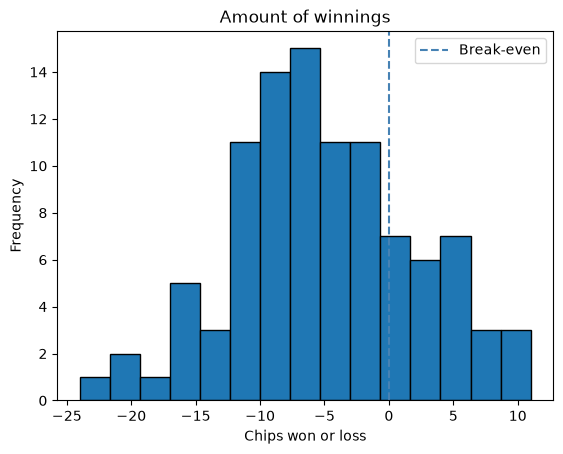

Threshold -6 -> Average total winnings:  -4.49 | Win percentage 22.00%
Threshold -4 -> Average total winnings:  -4.93 | Win percentage 21.00%
Threshold -2 -> Average total winnings:  -3.69 | Win percentage 25.00%
Threshold  0 -> Average total winnings:  -2.78 | Win percentage 32.00%
Threshold  2 -> Average total winnings:  -3.73 | Win percentage 24.00%
Threshold  4 -> Average total winnings:  -3.66 | Win percentage 24.00%
Threshold  6 -> Average total winnings:  -3.40 | Win percentage 28.00%


In [94]:
win_amount = [run_50_round_game(threshold=0, verbose=False) for _ in range(100)]
mean_for_round = np.mean(win_amount) / 50
std_dev = np.std(win_amount)
calc_win = np.mean([w > 0 for w in win_amount])
calc_loss = np.mean([w < 0 for w in win_amount])
print(f"Average winnings per round:, {mean_for_round:.4f}")
print(f"Standard Deviation: {std_dev:.2f}")
print(f"Prediction of amount win: {calc_win:.2%} | amount loss: {calc_loss:.2%}")
plt.hist(win_amount, bins=15, edgecolor="black")
plt.title("Amount of winnings")
plt.xlabel("Chips won or loss")
plt.ylabel("Frequency")
plt.axvline(0, color="steelblue", linestyle="dashed", label="Break-even")
plt.legend()
plt.show()
thresholds = [-6, -4, -2, 0, 2, 4, 6]
for t in thresholds:
    t_winnings = [run_50_round_game(threshold=t, verbose=False) for _ in range(100)]
    print(f"Threshold {t:2d} -> Average total winnings: {np.mean(t_winnings):6.2f} | Win percentage {np.mean([w > 0 for w in t_winnings]):.2%}")

In [95]:
individual_wins = []

for game_number in range(100):
    winnings = run_50_round_game(starting_chips=100, bet=1, verbose=False, player_class=IndividualPlayer)
    individual_wins.append(winnings)

Average wins: -4.87
STD: 6.7002313392897115
Standard Deviation: 6.98
Prediction of amount win: 0.0 | amount loss: 1.0


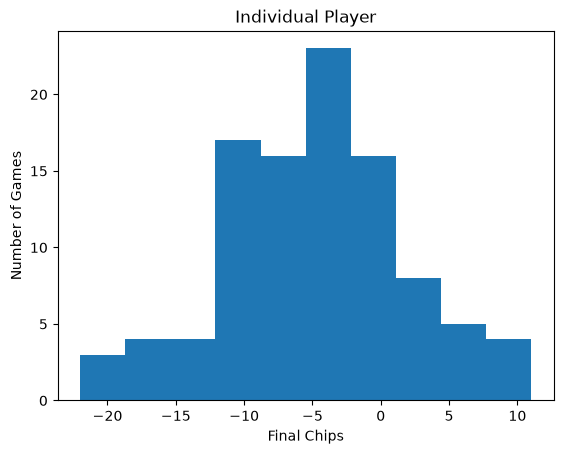

In [96]:


print("Average wins:", np.mean(individual_wins))
print("STD:", np.std(individual_wins))
print(f"Standard Deviation: {std_dev:.2f}")
print(f"Prediction of amount win: {np.mean(np.array(individual_wins) > 100)} | amount loss: {np.mean(np.array(individual_wins) < 100)}")
plt.hist(individual_wins)
plt.title("Individual Player")
plt.xlabel("Final Chips")
plt.ylabel("Number of Games")
plt.show()

In [89]:
def show_game(rounds=5):
    deck = Deck(num_decks=6)
    players = [
        DealerPlayer("Player 1", chips=100),
        DealerPlayer("Player 2", chips=100),
        DealerPlayer("Player 3", chips=100)
    ]
    dealer = DealerPlayer("Dealer", chips=100)
    for round_num in range(1, rounds + 1):
        print("Round", round_num)
        if deck.needs_shuffle:
           deck.build_and_shuffle()
           print("Deck is now shuffled")
        for player in players + [dealer]:
            player.hand = []
            for _ in range(2):
                player.hand.append(deck.draw())
        for player in players:
            print(player.name, player.hand)
            while player.hand_value() < 21 and player.decide_hit():
                new_card = deck.draw()
                player.hand.append(new_card)
                print(player.name, "hits:", new_card)
                print("Total:", player.hand_value())
            print("Final:", player.hand_value())
        print("Dealer's up")
        while dealer.hand_value() < 17:
            new_card = deck.draw()
            dealer.hand.append(new_card)
            print("Dealer hits:", new_card)
        dealer_total = dealer.hand_value()
        print("Dealer hand:", dealer.hand)
        print("Dealer total:", dealer_total)
        print("Results")
        for player in players:
            player_total = player.hand_value()
            if player_total > 21:
                player.chips -= 1
                print(player.name, "busts, Chips:", player.chips)
            elif dealer_total > 21 or player_total > dealer_total:
                player.chips += 1
                print(player.name, "is the Winner, Chips:", player.chips)
            elif player_total == dealer_total:
                print(player.name, "ties, Chips:", player.chips)
            else:
                player.chips -= 1
                print(player.name, "loses, Chips:", player.chips)
        print("Total chips left")
        for player in players:
            print(player.name, player.chips)

In [100]:
show_game(5)

Round 1
Player 1 [7C, 7S]
Player 1 hits: KS
Total: 24
Final: 24
Player 2 [KD, 4D]
Player 2 hits: QC
Total: 24
Final: 24
Player 3 [4D, 3D]
Player 3 hits: KH
Total: 17
Final: 17
Dealer's up
Dealer hand: [8H, AD]
Dealer total: 19
Results
Player 1 busts, Chips: 99
Player 2 busts, Chips: 99
Player 3 loses, Chips: 99
Total chips left
Player 1 99
Player 2 99
Player 3 99
Round 2
Player 1 [3C, AC]
Player 1 hits: 9D
Total: 13
Player 1 hits: QC
Total: 23
Final: 23
Player 2 [4C, 2C]
Player 2 hits: 5C
Total: 11
Player 2 hits: 2C
Total: 13
Player 2 hits: JD
Total: 23
Final: 23
Player 3 [2C, 8H]
Player 3 hits: 2D
Total: 12
Player 3 hits: 9D
Total: 21
Final: 21
Dealer's up
Dealer hand: [AS, KC]
Dealer total: 21
Results
Player 1 busts, Chips: 98
Player 2 busts, Chips: 98
Player 3 ties, Chips: 99
Total chips left
Player 1 98
Player 2 98
Player 3 99
Round 3
Player 1 [AS, 9D]
Final: 20
Player 2 [AC, 9S]
Final: 20
Player 3 [7D, 4H]
Player 3 hits: 9H
Total: 20
Final: 20
Dealer's up
Dealer hits: 6D
Dealer ha

In [ ]:
# In this lab I had trouble trying to setup the type of cards needed. 
# Hopefully I got the right classes inputed on here. There maybe some that might be unnecessary.
# I also used LLMS to check this lab. I ran into a few problems but I was able to fix them.